# Les 17 groupes de pavage — fermer un groupe, lire sa signature

**Navigation** : [Index du rayon](README.md) | [05-0 — générateurs symboliques](05-0-Generateurs-Symboliques.ipynb) | [05-0d — groupes de frise](05-0d-Groupes-De-Frise-Python.ipynb) | [05-0e — une seule règle de mesure](05-0e-MDL-Mesure-Unique-Python.ipynb)

Le carnet 05-0 décrit les **17 groupes de symétrie du plan** par leurs générateurs et affiche leurs invariants ; le carnet 05-0d fait le même travail en une dimension, sur les **7 groupes de frise**. Les deux lisent la structure dans une table que le moteur tient à côté des générateurs.

Ce carnet franchit l'étape qui manquait : **fermer** le groupe. On n'affiche plus une table écrite à côté, on calcule la structure sur l'**ensemble des transformations** reconstruit par composition des seuls générateurs. La **signature** du groupe sort de cet ensemble, et elle est confrontée à la dérivation d'attributs du même moteur : deux chemins de calcul, un seul verdict.

**Référence** : l'idée de lire un groupe sur l'ensemble de ses éléments vient d'un « coloring book » de théorie des groupes ([aberke/coloring-book](https://github.com/aberke/coloring-book)). Ce carnet ne reprend ni code ni figure : il rejoue le principe avec le moteur exact du dépôt ([`scripts/symmetry/`](../../../../scripts/symmetry/README.md)), qui ne consulte aucune table.

## La question : combien d'éléments dans un groupe infini ?

Un groupe de pavage est **infini** : il contient toutes les translations du réseau, et deux éléments de même partie linéaire ne diffèrent que par une de ces translations. Compter ses éléments n'a donc aucun sens.

Ce qui est fini, en revanche, c'est son **quotient par le réseau de translation**. On garde un représentant par classe — la partie linéaire, la translation ramenée dans la maille — puis on compose ces représentants entre eux en repliant chaque produit dans la maille. L'ensemble obtenu est fini, et c'est un groupe : l'**ensemble fermé**.

Deux faits tiennent tout le reste :

1. le cardinal de l'ensemble fermé est l'**ordre du groupe ponctuel** — le groupe formé par les parties linéaires ;
2. aucune rotation d'ordre autre que 1, 2, 3, 4 ou 6 ne laisse invariant un réseau du plan : c'est la **restriction cristallographique**, et c'est elle qui borne l'ensemble fermé.

La borne vaut donc 12, atteinte par le groupe le plus riche, `p6m`. Le moteur refuse explicitement un jeu de générateurs qui la dépasse, plutôt que de boucler — cette garde est exercée plus bas.

In [1]:
# Le moteur exact du depot : paquet scripts/symmetry, bibliotheque standard seule.
import sys
from fractions import Fraction
from pathlib import Path


def racine_du_depot(depart=Path.cwd()):
    """Remonter jusqu'au dossier qui contient le paquet scripts/symmetry."""
    for candidat in (depart, *depart.parents):
        if (candidat / "scripts" / "symmetry" / "__init__.py").is_file():
            return candidat
    raise RuntimeError("Paquet scripts/symmetry introuvable : executer le carnet depuis le depot.")


racine = racine_du_depot()
if str(racine / "scripts") not in sys.path:
    sys.path.insert(0, str(racine / "scripts"))

# L'API publique du paquet : aucun recopiage, on importe l'organe.
from symmetry import (
    GROUPS,
    GROUPS_BY_SYMBOL,
    attributes,
    closed_set,
    compare_with_attributes,
    order_of,
    render_svg,
    signature,
    translation_lattice,
    verify_all,
)
from symmetry.affine import Affine
from symmetry.closure import MAX_POINT_GROUP_ORDER, canonical, closure

print(f"groupes du plan    : {len(GROUPS)}")
print(f"symboles           : {', '.join(g.symbol for g in GROUPS)}")
print(f"borne de fermeture : {MAX_POINT_GROUP_ORDER} elements")

groupes du plan    : 17
symboles           : p1, p2, pm, pg, cm, pmm, pmg, pgg, cmm, p4, p4m, p4g, p3, p3m1, p31m, p6, p6m
borne de fermeture : 12 elements


## Pourquoi de l'arithmétique exacte

Toute la géométrie du moteur est en `fractions.Fraction` : une matrice, une translation sont des couples de rationnels, jamais des flottants. Ce n'est pas une coquetterie — deux pièges disparaissent avec l'exactitude, et les deux coûtent cher en virgule flottante.

1. **L'ordre d'un élément se lit sur ses puissances non réduites.** Le carré d'une glisse est une translation du réseau : replié dans la maille, il redevient l'identité. Un calcul naïf « composer jusqu'à retomber sur l'identité » conclut donc à l'ordre 2 pour un élément qui n'a aucun ordre fini comme isométrie du plan. L'ordre se lit sur l'élément, la fermeture se lit sur les classes ; les deux ne coïncident pas.

2. **Une classe de congruence peut porter un miroir et une glisse à la fois.** C'est le cas de `cm` : miroir et glisse y partagent une même direction, et l'ensemble fermé ne contient que deux éléments. Miroir ou glisse ne se décide donc jamais sur le représentant seul, mais sur les **droites** que le groupe contient.

Le premier piège se vérifie sur les données, immédiatement.

In [2]:
# Piege 1, mesure : le carre d'une glisse de pg est une translation du reseau.
# - comme isometrie du plan, la glisse n'a pas d'ordre fini (order_of rend 0) ;
# - comme CLASSE modulo le reseau, elle ferme en deux temps : son carre est
#   une translation du reseau, donc l'identite de la classe.
pg = GROUPS_BY_SYMBOL["pg"]
reseau_pg = translation_lattice(pg)
glisse = next(element for element in closed_set(pg) if not element.is_identity)
carre = glisse.compose(glisse)

print(f"glisse de pg         : partie lineaire {glisse.matrix}")
print(f"                       translation     {glisse.translation}")
print(f"glisse au carre      : translation     {carre.translation}")
print(f"translation pure     : {carre.is_pure_translation}")
print(f"ordre de la glisse   : {order_of(glisse)}   (0 = ordre infini du cote du plan)")
print(f"reseau de pg         : {reseau_pg}")
print(f"cardinal |pg / T|    : {len(closed_set(pg))}")

# Le carre replie dans la maille redonne l'identite : c'est ce qui ferme la classe.
print(f"carre replie         : identite = {canonical(carre, reseau_pg).is_identity}")

glisse de pg         : partie lineaire ((Fraction(1, 1), Fraction(0, 1)), (Fraction(0, 1), Fraction(-1, 1)))
                       translation     (Fraction(-1, 2), Fraction(0, 1))
glisse au carre      : translation     (Fraction(-1, 1), Fraction(0, 1))
translation pure     : True
ordre de la glisse   : 0   (0 = ordre infini du cote du plan)
reseau de pg         : ((Fraction(1, 1), Fraction(0, 1)), (Fraction(0, 1), Fraction(1, 1)))
cardinal |pg / T|    : 2
carre replie         : identite = True


## Fermer le groupe, depuis les seuls générateurs

`closed_set(groupe)` fait exactement ce que la section précédente décrit : il part de l'identité et des générateurs du groupe, compose tous les couples d'éléments déjà obtenus, replie chaque produit dans la maille, et recommence jusqu'à ce que l'ensemble ne grossisse plus.

Trois choses valent d'être regardées dans le résultat :

- le **cardinal** — c'est l'ordre du groupe ponctuel ;
- les **parties linéaires** — il doit y en avoir autant que d'éléments, une classe par transformation linéaire ;
- l'**identité** — elle doit être présente : sans elle, l'ensemble n'est pas un groupe.

Si l'ensemble dépasse la borne de 12, la fonction **lève une erreur** au lieu de boucler : un jeu de générateurs non cristallographiques est refusé, pas absorbé.

In [3]:
# Fermeture de p4m : identite + generateurs, composition de tous les couples,
# repli de chaque produit dans la maille, jusqu'a stabilite.
groupe = GROUPS_BY_SYMBOL["p4m"]
ferme = closed_set(groupe)
reseau = translation_lattice(groupe)

print(f"generateurs de p4m    : {len(groupe.generators)}")
print(f"cardinal |p4m / T|    : {len(ferme)}")
print(f"parties lineaires     : {len({element.matrix for element in ferme})} distinctes")
print(f"identite presente     : {any(element.is_identity for element in ferme)}")
print(f"reseau de translation : {reseau}")
print()
# Les huit elements, tries par partie lineaire puis par translation.
for element in sorted(ferme, key=lambda e: (e.matrix, e.translation)):
    print(f"  {element.matrix}  t={element.translation}  ordre={order_of(element)}")

generateurs de p4m    : 5
cardinal |p4m / T|    : 8
parties lineaires     : 8 distinctes
identite presente     : True
reseau de translation : ((Fraction(1, 1), Fraction(0, 1)), (Fraction(0, 1), Fraction(1, 1)))

  ((Fraction(-1, 1), Fraction(0, 1)), (Fraction(0, 1), Fraction(-1, 1)))  t=(Fraction(0, 1), Fraction(0, 1))  ordre=2
  ((Fraction(-1, 1), Fraction(0, 1)), (Fraction(0, 1), Fraction(1, 1)))  t=(Fraction(0, 1), Fraction(0, 1))  ordre=2
  ((Fraction(0, 1), Fraction(-1, 1)), (Fraction(-1, 1), Fraction(0, 1)))  t=(Fraction(0, 1), Fraction(0, 1))  ordre=2
  ((Fraction(0, 1), Fraction(-1, 1)), (Fraction(1, 1), Fraction(0, 1)))  t=(Fraction(0, 1), Fraction(0, 1))  ordre=4
  ((Fraction(0, 1), Fraction(1, 1)), (Fraction(-1, 1), Fraction(0, 1)))  t=(Fraction(0, 1), Fraction(0, 1))  ordre=4
  ((Fraction(0, 1), Fraction(1, 1)), (Fraction(1, 1), Fraction(0, 1)))  t=(Fraction(0, 1), Fraction(0, 1))  ordre=2
  ((Fraction(1, 1), Fraction(0, 1)), (Fraction(0, 1), Fraction(-1, 1)))  t=(Fraction(

## La signature : ce que l'ensemble fermé sait dire

Une fois l'ensemble fermé en main, `signature(groupe)` en extrait onze invariants, plus le symbole et le nom Conway qui ne servent qu'à l'affichage.

| Champ | Sens |
|---|---|
| `order` | cardinal de l'ensemble fermé, donc ordre du groupe ponctuel |
| `rotation_orders` / `rotations_by_order` | ordres de rotation présents, et nombre d'éléments de chaque ordre |
| `mirror_lines` / `mirror_directions` | droites de miroir par maille, et directions distinctes |
| `glide_axes` / `glide_directions` | axes de glisse par maille, et directions distinctes |
| `centers_by_order` | centres de rotation, comptés par ordre |
| `centers_off_mirrors` | centres qui ne sont sur aucune droite de miroir |
| `centers_on_glide_axes` | centres posés sur un axe de glisse |
| `total_centers` | total des centres de rotation |

Rien de tout cela n'est déclaré : chaque champ est **compté** sur les éléments de l'ensemble fermé. `key()` rend les onze invariants sous forme de tuple, sans le nom — deux groupes de même clé seraient le même groupe.

In [4]:
# Les 17 signatures, toutes lues sur l'ensemble ferme de chaque groupe.
# La colonne des rotations se lit "ordre x nombre d'elements" : 4x2 = deux
# elements d'ordre 4 dans la classe (un quart de tour et son inverse).
entete = (
    f"{'grp':5} {'Conway':7} {'|G/T|':>5} {'rotations (ordre x n)':21} "
    f"{'miroirs':>9} {'glisses':>9} {'centres':>8}"
)
print(entete)
print("-" * len(entete))

for groupe in GROUPS:
    sig = signature(groupe)
    rotations = "+".join(f"{ordre}x{nombre}" for ordre, nombre in sig.rotations_by_order) or "-"
    miroirs = f"{sig.mirror_lines}/{sig.mirror_directions}"
    glisses = f"{sig.glide_axes}/{sig.glide_directions}"
    print(
        f"{sig.symbol:5} {sig.conway:7} {sig.order:5} {rotations:21} "
        f"{miroirs:>9} {glisses:>9} {sig.total_centers:8}"
    )

print()
print("colonnes miroirs et glisses : lignes par maille / directions distinctes")

grp   Conway  |G/T| rotations (ordre x n)   miroirs   glisses  centres
----------------------------------------------------------------------
p1    o           1 -                           0/0       0/0        0
p2    2222        2 2x1                         0/0       0/0        4
pm    **          2 -                           2/1       0/0        0
pg    xx          2 -                           0/0       2/1        0
cm    *x          2 -                           1/1       1/1        0
pmm   *2222       4 2x1                         4/2       0/0        4
pmg   22*         4 2x1                         2/1       2/1        4
pgg   22x         4 2x1                         0/0       4/2        4


cmm   2*22        4 2x1                         2/2       2/2        4
p4    442         4 2x1+4x2                     0/0       0/0        4
p4m   *442        8 2x1+4x2                     6/4       2/2        4
p4g   4*2         8 2x1+4x2                     2/2       6/4        4
p3    333         3 3x2                         0/0       0/0        3


p3m1  *333        6 3x2                         3/3       3/3        3
p31m  3*3         6 3x2                         3/3       3/3        3
p6    632         6 2x1+3x2+6x2                 0/0       0/0        6


p6m   *632       12 2x1+3x2+6x2                 6/6       6/6        6

colonnes miroirs et glisses : lignes par maille / directions distinctes


### Lecture de la table

Trois lectures se dégagent, toutes vérifiables ligne à ligne dans la sortie ci-dessus.

**La colonne `|G/T|` est l'ordre du groupe ponctuel** — de 1 pour `p1` à 12 pour `p6m`. C'est la première moitié du théorème de la section précédente, et elle se lit ligne par ligne : chaque classe de l'ensemble fermé porte une partie linéaire différente, et toutes les parties linéaires du groupe y figurent.

**Les deux colonnes de symétries ne comptent pas la même chose.** `pmm` a quatre droites de miroir dans deux directions (4/2) ; `p4m` en a six dans quatre directions (6/4) : une direction contient plusieurs droites parallèles. Compter les directions suffit à nommer le groupe ; compter les droites décrit le motif.

**`p6` et `p6m` partagent leurs centres, pas leur position.** Les deux portent les mêmes classes de centres — trois d'ordre 2, deux d'ordre 3, un d'ordre 6 — mais `p6` n'a aucun miroir : ses six centres sont hors miroir par construction. Chez `p6m`, aucun centre n'est hors miroir : les six sont posés sur les droites. Même squelette de rotations, deux pavages différents.

## Deux groupes que les comptes ne séparent pas

`p3m1` et `p31m` sont les deux groupes hexagonaux à miroirs, et ils sont célèbres pour être confondus : mêmes rotations, mêmes miroirs, mêmes glisses, mêmes centres. La différence est un **placement**, pas un compte — et c'est exactement ce qu'une signature par invariants doit être capable de dire, sinon elle ne sert à rien.

On compare donc les deux signatures champ par champ, puis on rend les deux motifs.

In [5]:
# p3m1 contre p31m : memes comptes, placement des centres different.
p3m1, p31m = GROUPS_BY_SYMBOL["p3m1"], GROUPS_BY_SYMBOL["p31m"]

for groupe in (p3m1, p31m):
    sig = signature(groupe)
    print(
        f"{sig.symbol:5} miroirs={sig.mirror_lines}/{sig.mirror_directions} "
        f"glisses={sig.glide_axes}/{sig.glide_directions} "
        f"centres={sig.total_centers} "
        f"hors_miroirs={sig.centers_off_mirrors} "
        f"sur_glisses={sig.centers_on_glide_axes}"
    )

# Les onze invariants suffisent-ils a distinguer les deux groupes ?
print()
print("cles identiques   :", signature(p3m1).key() == signature(p31m).key())
print("champs divergents :", [
    champ
    for champ in signature(p31m).__dataclass_fields__
    if champ not in ("symbol", "conway")
    and getattr(signature(p3m1), champ) != getattr(signature(p31m), champ)
])

p3m1  miroirs=3/3 glisses=3/3 centres=3 hors_miroirs=0 sur_glisses=3
p31m  miroirs=3/3 glisses=3/3 centres=3 hors_miroirs=2 sur_glisses=1



cles identiques   : False


champs divergents : ['centers_off_mirrors', 'centers_on_glide_axes']


p3m1 -- *333


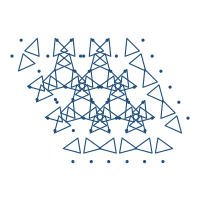

p31m -- 3*3


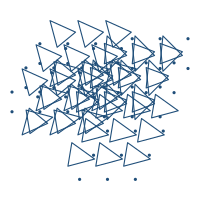

In [6]:
# Le rendu : l'orbite d'un motif asymetrique sous chaque groupe.
# Les deux images se ressemblent ; ce sont les centres qui les separent.
from IPython.display import SVG, display

for groupe in (p3m1, p31m):
    print(groupe.symbol, "--", signature(groupe).conway)
    display(SVG(render_svg(groupe, cells=2, size=200)))

### Lecture du résultat

Les deux groupes ont **le même compte de miroirs, de glisses et de centres**, et leurs clés diffèrent sur exactement deux champs : `centers_off_mirrors` (2 contre 0) et `centers_on_glide_axes` (1 contre 3).

C'est tout le contenu de la différence. Chez `p3m1`, les trois centres sont posés sur les droites de miroir ; chez `p31m`, deux des trois centres sont hors miroir et un seul est sur un axe de glisse. Un comptage de symétries — « trois miroirs, trois centres » — ne distingue donc pas les deux groupes ; seule la **position relative** des centres le fait. C'est ce que la signature mesure, et c'est ce qu'une table de comptes, seule, laisserait passer.

Les deux pavages rendus juste au-dessus se ressemblent à l'œil : même densité, même orientation des miroirs. Ce qui change est la place des centres de rotation **par rapport** à ces miroirs — les deux champs qui divergent dans la liste ci-dessus. Un œil qui compare deux images ne le voit pas ; la signature, si.

## Le second piège : `cm`, miroir et glisse dans la même direction

`pm` et `pg` sont les deux cas purs : des droites de miroir et aucune glisse pour l'un, des axes de glisse et aucun miroir pour l'autre. `cm`, lui, porte **une droite de miroir et un axe de glisse**, dans une même direction — et son ensemble fermé ne contient que deux éléments.

C'est le cas que le moteur documente comme piège : une classe de congruence peut porter les deux qualités à la fois. Décider « miroir ou glisse ? » en regardant le représentant choisi par la réduction donnerait une réponse fausse une fois sur deux ; les deux qualités sont donc rattachées aux **droites** du groupe, jamais au représentant seul.

In [7]:
# pm et pg sont les deux cas purs ; cm melange les deux dans une meme direction.
for symbole in ("pm", "pg", "cm"):
    sig = signature(GROUPS_BY_SYMBOL[symbole])
    print(
        f"{symbole:4} |G/T|={sig.order}  "
        f"miroirs={sig.mirror_lines}/{sig.mirror_directions}  "
        f"glisses={sig.glide_axes}/{sig.glide_directions}"
    )

# L'ensemble ferme de cm : deux elements seulement.
cm = GROUPS_BY_SYMBOL["cm"]
reseau_cm = translation_lattice(cm)
ferme_cm = sorted(closed_set(cm), key=lambda e: (e.matrix, e.translation))
print()
print(f"cardinal de cm : {len(ferme_cm)}")
for element in ferme_cm:
    print(f"  {element.matrix}  t={element.translation}")

# Le representant non trivial, replie dans la maille : un miroir pur.
representant = next(element for element in ferme_cm if not element.is_identity)
replie = canonical(representant, reseau_cm)
print()
print(f"reseau de cm                : {reseau_cm}")
print(f"translation du representant : {representant.translation}")
print(f"repliee dans la maille      : {replie.translation}")

pm   |G/T|=2  miroirs=2/1  glisses=0/0
pg   |G/T|=2  miroirs=0/0  glisses=2/1
cm   |G/T|=2  miroirs=1/1  glisses=1/1

cardinal de cm : 2
  ((Fraction(-1, 1), Fraction(0, 1)), (Fraction(0, 1), Fraction(1, 1)))  t=(Fraction(0, 1), Fraction(0, 1))
  ((Fraction(1, 1), Fraction(0, 1)), (Fraction(0, 1), Fraction(1, 1)))  t=(Fraction(0, 1), Fraction(0, 1))

reseau de cm                : ((Fraction(0, 1), Fraction(1, 1)), (Fraction(1, 2), Fraction(-1, 2)))
translation du representant : (Fraction(0, 1), Fraction(0, 1))
repliee dans la maille      : (Fraction(0, 1), Fraction(0, 1))


### Lecture du résultat

`pm` et `pg` sont nets : l'un ne compte que des miroirs, l'autre que des glisses, et chacun peut être décrit par un seul représentant. `cm` ne le peut pas.

Le représentant canonique de `cm` se replie sur la **translation nulle** : c'est le miroir pur, la partie linéaire `(-1, 1)` appliquée à l'origine. Et pourtant la signature compte **un axe de glisse en plus** de la droite de miroir, alors que l'ensemble fermé ne compte que deux éléments : il n'y a donc pas, dans cet ensemble, un élément « miroir » et un élément « glisse » à ranger dans deux colonnes.

Miroir et glisse sont deux qualités portées par les **droites** du groupe, dans une même direction — c'est la convention que documente `symmetry/closure.py`, et c'est pourquoi la signature compte des droites et des directions, et non des éléments. Un moteur qui aurait classé les éléments aurait compté `cm` comme un groupe à miroirs, et perdu le second axe de glisse.

## Contre-épreuve : deux dérivations, et une garde qui mord

Le moteur dérive les mêmes invariants par deux chemins : la **fermeture** (`signature`, qui lit l'ensemble fermé) et la **dérivation d'attributs** de `wallpaper` (`attributes`, qui part des générateurs par les formules de cristallographie). `compare_with_attributes(groupe)` rend les champs sur lesquels les deux chemins divergent.

Sur les 17 groupes, il ne rend rien. C'est un accord entre deux **méthodes** — pas une preuve que les générateurs sont justes : les deux chemins partent des mêmes générateurs, donc une erreur de générateur les déplacerait ensemble. Ce que l'accord élimine, c'est l'erreur de méthode (une formule fausse, un comptage faux) ; ce qu'il n'élimine pas, c'est l'erreur de donnée.

La garde qui mord est d'une autre nature : un jeu de générateurs qui n'engendre pas un groupe fini modulo le réseau est **refusé**, pas absorbé. On l'exerce avec une partie linéaire d'ordre infini — une cisaille.

In [8]:
# Deux derivations independantes : la fermeture, et les attributs du moteur.
ecarts = {}
for groupe in GROUPS:
    differences = compare_with_attributes(groupe)
    if differences:
        ecarts[groupe.symbol] = differences

print(f"groupes ou les deux derivations divergent : {len(ecarts)}")
print(f"verdict de verify_all()                   : {verify_all()}")

# La garde : une partie lineaire d'ordre infini ne ferme pas modulo le reseau.
# La cisaille (1,1;0,1) decale chaque application d'une unite en x : ses
# puissances n'ont pas de periode, donc l'ensemble ne se stabilise pas.
cisaille = Affine.linear(((Fraction(1), Fraction(1)), (Fraction(0), Fraction(1))))
generateurs = (
    Affine.translation(1, 0),
    Affine.translation(0, 1),
    cisaille,
)
try:
    ensemble = closure(generateurs, ((Fraction(1), Fraction(0)), (Fraction(0), Fraction(1))))
    print(f"ensemble ferme : {len(ensemble)} elements -- la garde n'a pas mordu")
except ValueError as erreur:
    print(f"refus du moteur : {erreur}")

groupes ou les deux derivations divergent : 0


verdict de verify_all()                   : {}
refus du moteur : ensemble non fini modulo le reseau : 17 elements, plus que la borne 12 -- generateurs non cristallographiques


### Lecture du résultat

Les deux dérivations s'accordent sur les 17 groupes : aucun champ divergent, et `verify_all()` ne signale rien. L'accord est donc **méthodologique**, comme dit plus haut — il porte sur la cohérence entre deux façons de calculer, pas sur la justesse des générateurs.

La garde, elle, produit bien un refus : la cisaille ne se stabilise pas modulo le réseau, et le moteur le dit plutôt que de renvoyer un ensemble faux. Le message porte le nombre d'éléments atteints et la borne : un diagnostic, pas une exception opaque.

Un moteur de géométrie exacte se juge donc sur deux questions : ses méthodes s'accordent-elles entre elles (ici oui, sur les 17 groupes) et refuse-t-il ce qu'il ne sait pas traiter (ici oui, la cisaille) ?

## Exercice 1 — l'ordre maximal d'un groupe

Un groupe de pavage n'a pas d'ordre fini : il est infini par ses translations. Ce qu'il a, c'est un **ordre maximal des éléments de sa classe** : le plus grand ordre d'une rotation ou d'un miroir pris dans l'ensemble fermé.

Écrivez `ordre_maximal(groupe)` qui renvoie cet ordre pour un groupe donné, et `0` quand le groupe n'a que l'identité (c'est le cas de `p1`).

In [9]:
def ordre_maximal(groupe) -> int:
    """Ordre maximal d'un element non identite de l'ensemble ferme du groupe.

    Renvoie 0 quand l'ensemble ferme ne contient que l'identite.
    """
    # Etape 1 : fermer le groupe (closed_set)
    # Etape 2 : ne garder que les elements qui ne sont pas l'identite
    # Etape 3 : prendre le plus grand de leurs ordres (order_of)
    # Indice : max(..., default=0) sur un generateur vide rend 0
    resultat = None  # TODO etudiant
    return resultat


# Verification sur quelques groupes : la reponse attendue se lit sur la
# colonne des rotations de la table du carnet.
if ordre_maximal(GROUPS_BY_SYMBOL["p4m"]) is None:
    print("Exercice 1 a completer")
else:
    for symbole in ("p1", "p2", "p3", "p4", "p6", "p6m"):
        print(f"{symbole:4} ordre maximal : {ordre_maximal(GROUPS_BY_SYMBOL[symbole])}")

Exercice 1 a completer


## Exercice 2 — chiralité : un groupe sans miroir ni glisse

Un groupe de symétrie du plan est **chiral** quand il ne contient aucune symétrie qui renverse l'orientation : ni miroir, ni glisse. Un groupe chiral ne peut pas être superposé à son image miroir par une isométrie — c'est le critère qui distingue, en chimie, une molécule chirale de son image.

Écrivez `est_chirale(groupe)` qui renvoie `True` pour un groupe chiral, `False` sinon.

In [10]:
def est_chirale(groupe) -> bool:
    """Vrai si le groupe ne contient ni miroir ni glisse.

    Un groupe chiral n'admet aucune symetrie d'orientation inversante :
    son image miroir n'est pas superposable a lui-meme.
    """
    # Etape 1 : signer le groupe (signature)
    # Etape 2 : le groupe est chiral si mirror_lines == 0 ET glide_axes == 0
    # Indice : un centre de rotation est une symetrie d'orientation
    #           PRESERVANTE, pas un miroir -- ne compte pas comme miroir.
    resultat = None  # TODO etudiant
    return resultat


# Verification : la liste des groupes chiraux se lit sur la table du carnet
# (ceux dont les deux colonnes de symetries sont a zero).
if est_chirale(GROUPS_BY_SYMBOL["p1"]) is None:
    print("Exercice 2 a completer")
else:
    chiraux = [groupe.symbol for groupe in GROUPS if est_chirale(groupe)]
    print(f"groupes chiraux : {', '.join(chiraux)}")

Exercice 2 a completer


## Exercice 3 — quels invariants séparent deux groupes ?

On a vu que `p3m1` et `p31m` ont les mêmes comptes et des signatures différentes. Rendez cette comparaison utilisable : écrivez `champs_divergents(a, b)` qui renvoie la **liste des noms d'invariants** qui diffèrent entre deux groupes, dans l'ordre de `CHAMPS`.

La liste `CHAMPS` est donnée ci-dessous : elle reprend les onze invariants de `GroupSignature.key()`, dans le même ordre.

In [11]:
# Les onze invariants, dans l'ordre de GroupSignature.key()
CHAMPS = (
    "order",
    "rotation_orders",
    "rotations_by_order",
    "mirror_lines",
    "mirror_directions",
    "glide_axes",
    "glide_directions",
    "centers_by_order",
    "centers_off_mirrors",
    "centers_on_glide_axes",
    "total_centers",
)


def champs_divergents(a, b) -> list[str]:
    """Noms des invariants qui different entre les signatures de deux groupes."""
    # Etape 1 : signer les deux groupes (signature)
    # Etape 2 : parcourir CHAMPS et retenir les champs dont les valeurs different
    # Indice : getattr(signature(a), champ) != getattr(signature(b), champ)
    resultat = None  # TODO etudiant
    return resultat


# Verification : le resultat attendu pour p3m1 contre p31m se lit dans la
# section « Deux groupes que les comptes ne separent pas ».
if champs_divergents(GROUPS_BY_SYMBOL["p3m1"], GROUPS_BY_SYMBOL["p31m"]) is None:
    print("Exercice 3 a completer")
else:
    print(
        "p3m1 contre p31m   :",
        champs_divergents(GROUPS_BY_SYMBOL["p3m1"], GROUPS_BY_SYMBOL["p31m"]),
    )
    print(
        "p4m contre lui-meme :",
        champs_divergents(GROUPS_BY_SYMBOL["p4m"], GROUPS_BY_SYMBOL["p4m"]),
    )

Exercice 3 a completer


## Ce qu'on a appris

- Un groupe de pavage est infini, mais son **quotient par le réseau de translation** est fini : c'est l'ensemble fermé, et son cardinal est l'ordre du groupe ponctuel.
- La **signature** se lit sur cet ensemble : onze invariants comptés, aucun recopié d'une table. `key()` est ce qui distingue deux groupes.
- Les **comptes** ne suffisent pas : `p3m1` et `p31m` ont les mêmes comptes et des signatures différentes ; la différence tient à la **position** des centres par rapport aux miroirs.
- **Miroir ou glisse** ne se décide pas sur un représentant : `cm` porte les deux dans une même direction, et c'est la droite qui porte la qualité.
- Un moteur exact se juge à deux questions : ses méthodes s'accordent-elles entre elles, et refuse-t-il ce qu'il ne sait pas traiter.

**Pour aller plus loin**

- Le cas 1D de la même démarche — les 7 groupes de frise — dans [05-0d](05-0d-Groupes-De-Frise-Python.ipynb) : même logique de signature, en dimension 1.
- Le moteur lui-même : [`scripts/symmetry/`](../../../../scripts/symmetry/README.md) — algèbre affine, les 17 groupes, la fermeture et ses tests.
- La version formelle d'un groupe ponctuel : le compagnon Lean [`WallpaperP4m.lean`](../../../SymbolicAI/Lean/mathlib_examples/MathLibExamples/WallpaperP4m.lean), qui prouve le groupe ponctuel de `p4m` et distingue ses symétries des translations infinies du pavage.
- Les rosaces `C_n` et `D_n` du même rayon : [`symmetry_art.py`](symmetry_art.py).

**Source de l'idée** : [aberke/coloring-book](https://github.com/aberke/coloring-book) (« A Coloring Book about Group Theory ») — inspiration citée, aucun code ni asset repris.

In [12]:
# Recapitulatif mesure : les 17 groupes se ferment, et leurs cles sont distinctes.
cles = {groupe.symbol: signature(groupe).key() for groupe in GROUPS}

print(f"groupes fermes         : {len(cles)}")
print(f"cles distinctes        : {len(set(cles.values()))}")
print(f"ordre ponctuel maximal : {max(signature(groupe).order for groupe in GROUPS)}")
print(f"ecarts entre derivations : {verify_all() or 'aucun'}")

groupes fermes         : 17
cles distinctes        : 17


ordre ponctuel maximal : 12


ecarts entre derivations : aucun
